C:\Users\kkume\AppData\Local\Temp\ipykernel_31564\2009630063.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_finance, x='League', y='Avg_Club_Revenue_mGBP', ax=ax1, palette=['#4E79A7', '#F28E2B'])
C:\Users\kkume\AppData\Local\Temp\ipykernel_31564\2009630063.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_finance, x='League', y='Avg_Player_Weekly_Wage_GBP', ax=ax2, palette=['#4E79A7', '#F28E2B'])
C:\Users\kkume\AppData\Local\Temp\ipykernel_31564\2009630063.py:35: UserWarning: Glyph 48512 (\N{HANGUL SYLLABLE BU}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\kkume\AppData\Local\Temp\ipykernel_31564\2009630063.py:36: UserWarning: Glyph 48512 (\N{HANGUL SY

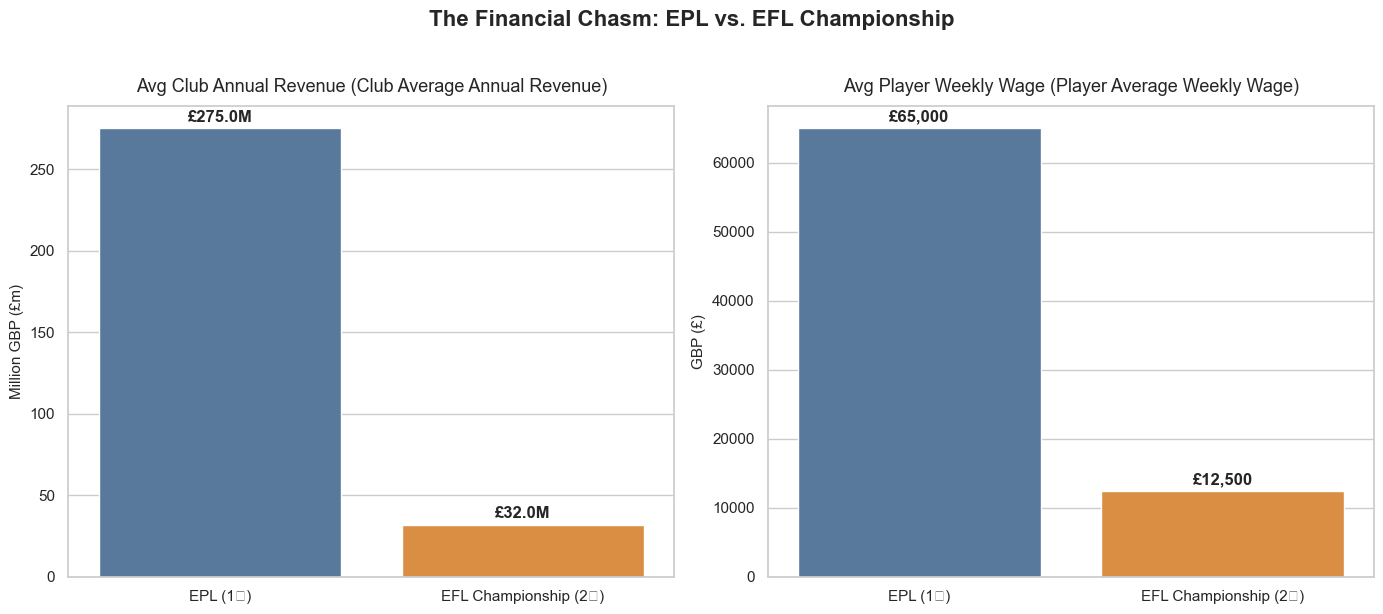

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 데이터 불러오기
df_finance = pd.read_csv('EPL_vs_EFL_Financial_Comparison.csv')

# 그래프 스타일 설정
sns.set_theme(style="whitegrid")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# 1. 구단 평균 수입 비교 (좌측 그래프)
sns.barplot(data=df_finance, x='League', y='Avg_Club_Revenue_mGBP', ax=ax1, palette=['#4E79A7', '#F28E2B'])
ax1.set_title('Avg Club Annual Revenue (Club Average Annual Revenue)', fontsize=13, pad=10)
ax1.set_ylabel('Million GBP (£m)', fontsize=11)
ax1.set_xlabel('')

# 각 막대 위에 수치 표시
for p in ax1.patches:
    ax1.annotate(f"£{p.get_height():.1f}M", (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontweight='bold')

# 2. 선수 평균 주급 비교 (우측 그래프)
sns.barplot(data=df_finance, x='League', y='Avg_Player_Weekly_Wage_GBP', ax=ax2, palette=['#4E79A7', '#F28E2B'])
ax2.set_title('Avg Player Weekly Wage (Player Average Weekly Wage)', fontsize=13, pad=10)
ax2.set_ylabel('GBP (£)', fontsize=11)
ax2.set_xlabel('')

# 각 막대 위에 수치 표시
for p in ax2.patches:
    ax2.annotate(f"£{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontweight='bold')

plt.suptitle('The Financial Chasm: EPL vs. EFL Championship', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('EPL_vs_EFL_Financial_Gap.png', bbox_inches='tight')
plt.show()

In [ ]:
import pandas as pd
#pip install pandas numpy statsmodels matplotlib seaborn scikit-learn
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error

# 1. 데이터 로드
url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
insurance = pd.read_csv(url)

# 2. VIF 확인 (R의 car::vif 대응)
# 수치형 변수만 선택하여 VIF 계산
from statsmodels.stats.outliers_influence import variance_inflation_factor
X_vif = insurance[['age', 'bmi', 'children']]
vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(len(X_vif.columns))]
print(vif_data)

# 3. EDA (시각화)
sns.pairplot(insurance[['charges', 'age', 'bmi', 'children']])
plt.show()

sns.scatterplot(data=insurance, x='age', y='charges', hue='smoker')
plt.show()

# 4. 모델 생성 (R의 model1과 유사하게 로그 변환 및 상호작용 항 포함)
# statsmodels는 formula 문법을 지원합니다.
formula = """np.log(charges) ~ age + I(age**2) + sex + bmi + I(bmi**2) + 
             children + smoker + region + age:sex + age:children + 
             age:smoker + age:region + sex:smoker + bmi:smoker + 
             children:smoker + smoker:region"""

model1 = smf.ols(formula, data=insurance).fit()
print(model1.summary())

# 5. 예측 (New Person)
new_person = pd.DataFrame({
    'age': [27], 'bmi': [28], 'children': [0],
    'sex': ['male'], 'smoker': ['no'], 'region': ['southwest']
})

# 예측값 및 신뢰구간
pred = model1.get_prediction(new_person)
pred_summary = pred.summary_frame(alpha=0.05)

# 로그 스케일에서 원래 단위로 변환
print("예측값 (exp):", np.exp(pred_summary[['mean', 'obs_ci_lower', 'obs_ci_upper']]))

# 6. 진단 그래프 (QQ 및 잔차)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sm.qqplot(model1.resid, line='s', ax=ax[0])
ax[0].set_title("QQ Plot")
ax[1].scatter(model1.fittedvalues, model1.resid)
ax[1].set_title("Residuals vs Fitted")
plt.show()

ModuleNotFoundError: No module named 'statsmodels'

: 